In [10]:
import jieba
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

stopwords_path = "/Users/fengqiukai/Downloads/data/case4/stopwords.txt"

stop = set(open(stopwords_path, encoding="utf-8").read().split())

years = [2022, 2023, 2024, 2025, 2026]

def seg(text):
    return " ".join(
        w for w in jieba.lcut(text)
        if len(w) > 1
        and w not in stop
        and not any(c.isdigit() for c in w)
    )

docs = [
    seg(open(
        f"/Users/fengqiukai/Downloads/data/case4/{y}_政府工作报告.txt",
        encoding="utf-8"
    ).read())
    for y in years
]

for year, doc in zip(years, docs):
    print(f"{year}年政府工作报告：")
    print(doc)
    print()

2022年政府工作报告：
国务院 政府 工作 报告 全文 来源 中国政府 https www gov cn premier content htm 新华社 北京 日电 政府 工作 报告 第十三届 全国人民代表大会 第五次 会议 国务院 总理 李克强 李克强 总理 代表 国务院 十三届 全国人大 五次 会议 上作 政府 工作 报告 新华社 记者 姚大伟 代表 现在 代表 国务院 大会 报告 政府 工作 请予 审议 全国政协 委员 提出 意见 工作 回顾 过去 一年 党和国家 历史 具有 里程碑 意义 一年 习近平 同志 核心 党中央 团结 带领 全党全国 各族人民 隆重庆祝 中国共产党 成立 一百周年 胜利 召开 十九 六中全会 制定 第三个 历史 决议 如期 打赢 脱贫 攻坚战 如期 全面 建成 小康社会 实现 第一个 百年 奋斗目标 开启 全面 建设 社会主义 现代化 国家 第二个 百年 奋斗目标 进军 征程 一年 面对 复杂 严峻 国内外 形势 诸多 风险 挑战 全国上下 共同努力 统筹 疫情 防控 经济社会 发展 全年 主要 目标 任务 完成 十四五 实现 良好 开局 我国 发展 取得 重大成就 经济 保持 恢复 发展 国内 生产总值 达到 万亿元 增长 全国 财政收入 突破 万亿元 增长 城镇 新增 就业 万人 城镇 调查 失业率 平均 居民消费 价格上涨 国际收支 基本 平衡 创新能力 进一步 增强 国家 战略 科技 力量 加快 壮大 关键 核心技术 攻关 取得 重要 进展 载人 航天 火星 探测 资源 勘探 能源 工程 领域 实现 突破 企业 研发 经费 增长 数字 技术 实体 经济 加速 融合 经济 结构 区域 布局 继续 优化 粮食产量 万亿斤 历史 新高 高技术 制造业 增加值 增长 信息技术 服务 生产性 服务业 发展 产业链 韧性 得到 提升 区域 发展 战略 有效 实施 新型 城镇化 扎实 推进 改革开放 不断 深化 重要 领域 关键环节 推出 一批 重大 改革 举措 供给 结构性 改革 深入 推进 放管服 改革 取得 新进展 市场主体 总量 超过 亿户 高质量 共建 一带 一路 稳步 推进 推动 区域 全面 经济 伙伴关系 协定 生效 实施 货物 进出口 总额 增长 实际 使用 外资 保持 增长 生态 文明 建设 持续 推进 污染 防治 攻

In [11]:

vec = TfidfVectorizer(
    max_df=0.9,
    min_df=1,
    token_pattern=r"(?u)\S+"
)

X = vec.fit_transform(docs)
terms = vec.get_feature_names_out()

print("矩阵形状：", X.shape)

矩阵形状： (5, 3628)


In [13]:

top = {}

for i, y in enumerate(years):
    scores = X[i].toarray().ravel()
    idx = scores.argsort()[::-1][:10]
    top[y] = [terms[j] for j in idx]

df = pd.DataFrame.from_dict(top, orient="index")
df.columns = [f"Top{i}" for i in range(1, 11)]
df.index.name = "年份"

display(df)

,Top1,Top2,Top3,Top4,Top5,Top6,Top7,Top8,Top9,Top10
年份,,,,,,,,,,
2022,疫情,退税,市场主体,实行,减税,恢复,留抵,疫苗,十九,严重
2023,疫情,年均,万公里,五年,降费,降至,压减,减税,货物,退税
2024,打造,房地产,需要,大力发展,恢复,自贸,数据,深入开展,回升,宏观调控
2025,上年,大力发展,更大,三中全会,检查,收官,调整机制,二中,渠道,打造
2026,着眼,纲要,十五,草案,自主,指标,智能,要素,成效,打造


In [14]:

for a, b in zip(years[:-1], years[1:]):
    print(f"{b} 相对 {a} 新出现：", set(top[b]) - set(top[a]))
    print(f"{a}-{b} 共有：", set(top[b]) & set(top[a]))

2023 相对 2022 新出现： {'降至', '万公里', '年均', '降费', '货物', '压减', '五年'}
2022-2023 共有： {'疫情', '减税', '退税'}
2024 相对 2023 新出现： {'大力发展', '数据', '宏观调控', '自贸', '恢复', '深入开展', '需要', '房地产', '回升', '打造'}
2023-2024 共有： set()
2025 相对 2024 新出现： {'调整机制', '三中全会', '二中', '上年', '渠道', '收官', '更大', '检查'}
2024-2025 共有： {'大力发展', '打造'}
2026 相对 2025 新出现： {'草案', '指标', '智能', '要素', '十五', '自主', '着眼', '成效', '纲要'}
2025-2026 共有： {'打造'}


In [16]:
%pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 1.8 MB/s  0:00:01 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [17]:
import jieba
import jieba.analyse as ja
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

gov_2026 = "/Users/fengqiukai/Downloads/data/case4/2026_政府工作报告.txt"
stopwords_path = "/Users/fengqiukai/Downloads/data/case4/stopwords.txt"

text = open(gov_2026, encoding="utf-8").read()
ja.set_stop_words(stopwords_path)

# TextRank 提取 Top20
for w, s in ja.textrank(text, topK=20, withWeight=True):
    print(w, round(s, 3))

发展 1.0
建设 0.707
推进 0.612
加强 0.505
实施 0.459
政策 0.407
加快 0.361
支持 0.346
推动 0.336
提升 0.331
经济 0.313
促进 0.307
完善 0.293
改革 0.29
社会 0.261
领域 0.258
提高 0.257
创新 0.252
服务 0.246
重点 0.246


In [19]:

print("默认：", ja.textrank(text, topK=20))

print(
    "仅名词类：",
    ja.textrank(
        text,
        topK=20,
        allowPOS=("n", "ns", "nt", "nz")
    )
)

默认： ['发展', '建设', '推进', '加强', '实施', '政策', '加快', '支持', '推动', '提升', '经济', '促进', '完善', '改革', '社会', '领域', '提高', '创新', '服务', '重点']
仅名词类： ['政策', '经济', '领域', '重点', '国家', '政府', '科技', '社会', '中国', '全面', '体系', '高质量', '机制', '产业', '制度', '能力', '地方', '战略', '风险', '工程']


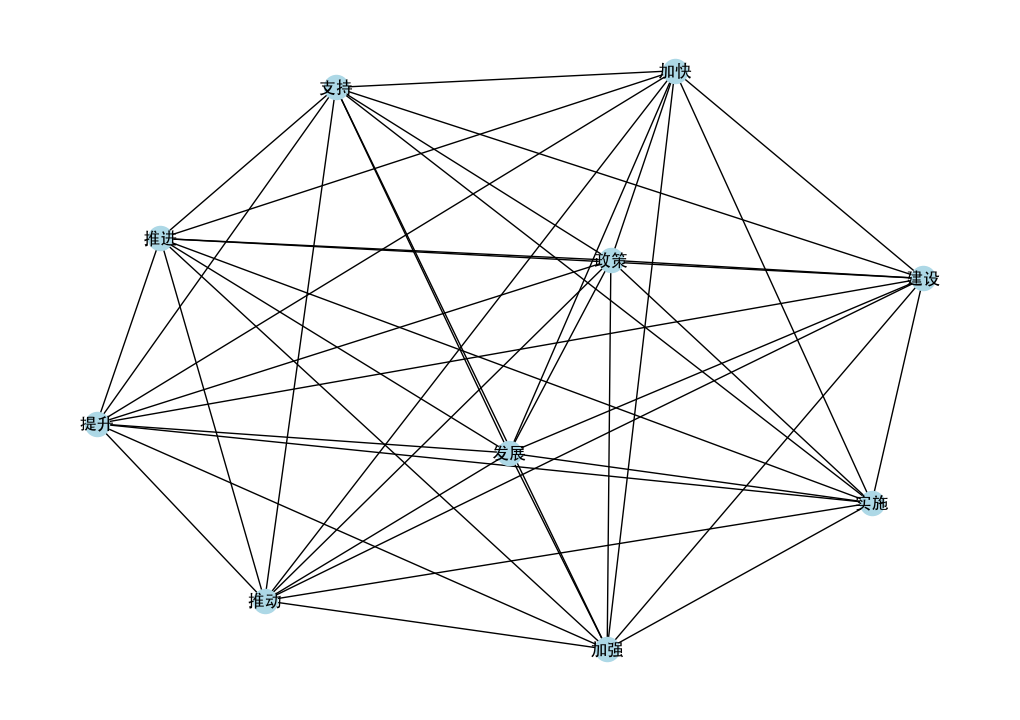

In [20]:
from matplotlib import font_manager

font_path = "/System/Library/Fonts/STHeiti Medium.ttc"
font_manager.fontManager.addfont(font_path)
font_name = font_manager.FontProperties(fname=font_path).get_name()

top10 = [w for w, _ in ja.textrank(text, topK=10, withWeight=True)]

seq = [w for w in jieba.lcut(text) if w in top10]

G2 = nx.Graph()

for i in range(len(seq)):
    for j in range(i + 1, min(i + 5, len(seq))):
        if seq[i] != seq[j]:
            G2.add_edge(seq[i], seq[j])

plt.figure(figsize=(10, 7))

nx.draw(
    G2,
    with_labels=True,
    font_family=font_name,
    node_color="lightblue"
)

plt.savefig(
    "/Users/fengqiukai/Downloads/textrank_graph.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()